In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/hotel_bookings.csv")

print("Dataset shape:", df.shape)
display(df.head())

print("\nDataset information:")
df.info()


Dataset shape: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  

Missing Values:
company                           112593
agent                              16340
country                              488
children                               4
arrival_date_month                     0
arrival_date_week_number               0
hotel                                  0
is_canceled                            0
stays_in_weekend_nights                0
arrival_date_day_of_month              0
adults                                 0
stays_in_week_nights                   0
babies                                 0
meal                                   0
lead_time                              0
arrival_date_year                      0
distribution_channel                   0
market_segment                         0
previous_bookings_not_canceled         0
is_repeated_guest                      0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
previous_cancellations                 0


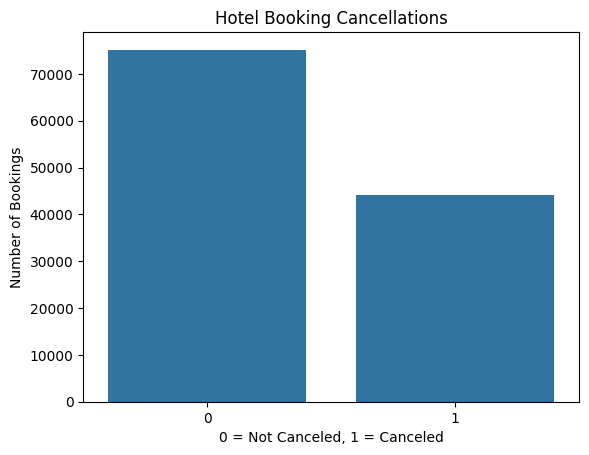

In [ ]:

# Check missing values in each column
print("Missing Values:")
print(df.isnull().sum().sort_values(ascending=False))

# Count canceled and non-canceled bookings
print("\nBooking Cancellations:")
print(df["is_canceled"].value_counts())

# Visualize cancellations
sns.countplot(data=df, x="is_canceled")

plt.title("Hotel Booking Cancellations")
plt.xlabel("0 = Not Canceled, 1 = Canceled")
plt.ylabel("Number of Bookings")
plt.show()


### Step 2: Data Exploration

The dataset was examined to identify missing values and understand the distribution of booking cancellations.

The target variable is `is_canceled`, where 0 represents a booking that was not canceled and 1 represents a canceled booking.

The distribution shows that non-canceled bookings are more common than canceled bookings. This class imbalance will be considered during model evaluation.

In [ ]:

# Make a copy of the dataset
df_clean = df.copy()

# Remove columns that reveal the booking outcome
df_clean = df_clean.drop(columns=[
    "reservation_status",
    "reservation_status_date"
])

print("Original columns:", df.shape[1])
print("Remaining columns:", df_clean.shape[1])

display(df_clean.head())


Original columns: 32
Remaining columns: 30


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1


### Step 3: Preventing Data Leakage

Data leakage occurs when a machine learning model uses information that would not be available at the time of prediction.

The columns `reservation_status` and `reservation_status_date` were removed because they contain information about the final booking outcome.

Removing these columns helps ensure that the model makes predictions using appropriate information rather than knowing the outcome in advance.





In [ ]:

from sklearn.model_selection import train_test_split

# Separate features and target
X = df_clean.drop("is_canceled", axis=1)
y = df_clean["is_canceled"]

# Split the dataset: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 95512
Testing samples: 23878


### Step 4: Train-Test Split

The dataset was divided into 80% training data and 20% testing data.

The training set contains 95,512 bookings, while the testing set contains 23,878 bookings.

Stratified sampling was used to preserve the proportion of canceled and non-canceled bookings in both datasets.

The testing data will be used to evaluate the model's performance on unseen examples.

In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify numerical and categorical columns
numeric_cols = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_cols = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Process numerical features
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Process categorical features
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

print("Numerical features:", len(numeric_cols))
print("Categorical features:", len(categorical_cols))
print("Preprocessing pipeline created successfully!")


Numerical features: 19
Categorical features: 10
Preprocessing pipeline created successfully!


### Step 5: Data Preprocessing

A preprocessing pipeline was created to prepare numerical and categorical features for machine learning.

Missing numerical values will be replaced using median imputation, while missing categorical values will be replaced with the most frequent category.

Categorical variables will be converted into numerical representations using One-Hot Encoding. Numerical features will be standardized using StandardScaler.

All preprocessing transformations will be fitted only on the training data to prevent data leakage.

In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Create the complete model
lr_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        solver="liblinear"
    ))
])

# Train the model
lr_model.fit(X_train, y_train)

# Make predictions
y_pred = lr_model.predict(X_test)

print("Logistic Regression trained successfully!")


Logistic Regression trained successfully!


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1-score:", round(f1_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Accuracy: 0.8192
Precision: 0.8128
Recall: 0.665
F1-score: 0.7315

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.91      0.86     15033
           1       0.81      0.67      0.73      8845

    accuracy                           0.82     23878
   macro avg       0.82      0.79      0.80     23878
weighted avg       0.82      0.82      0.81     23878



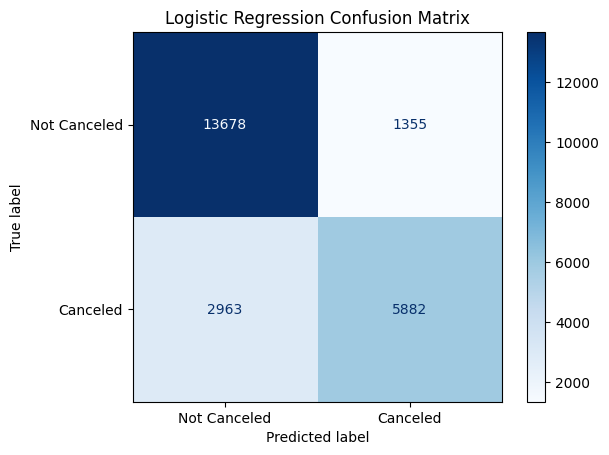

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Not Canceled", "Canceled"],
    cmap="Blues"
)

plt.title("Logistic Regression Confusion Matrix")
plt.show()


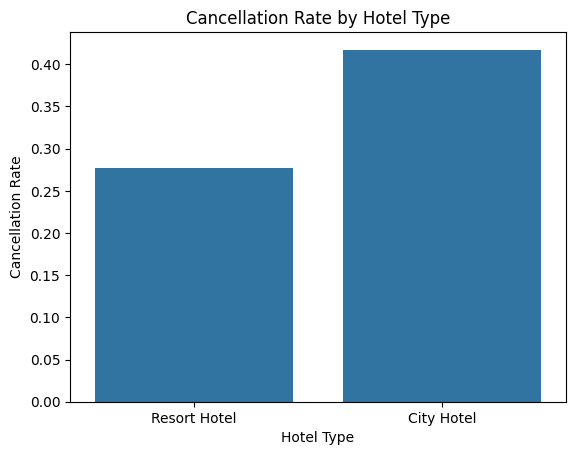

In [ ]:
sns.barplot(
    data=df,
    x="hotel",
    y="is_canceled",
    errorbar=None
)

plt.title("Cancellation Rate by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Cancellation Rate")
plt.show()


### Step 6: Logistic Regression Model

Logistic Regression was used as the baseline model for predicting hotel booking cancellations.

The model was trained using 80% of the dataset and evaluated on the remaining 20%.

A preprocessing pipeline was used to handle missing values, encode categorical features, and scale numerical features without data leakage.

The model was evaluated using accuracy, precision, recall, F1-score, and a confusion matrix.

These metrics help evaluate both overall prediction accuracy and the model's ability to identify canceled bookings.

In [ ]:
Block b

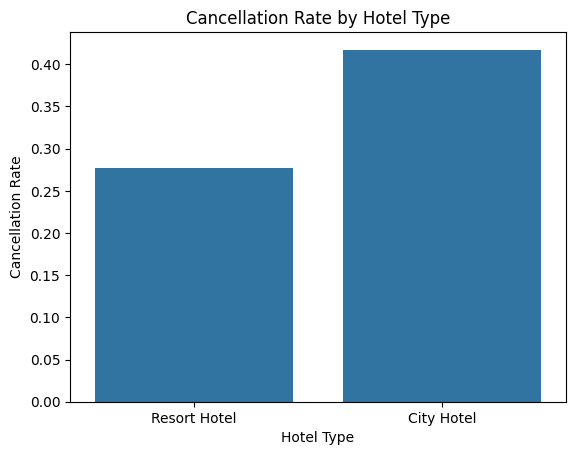

In [ ]:

sns.barplot(
    data=df,
    x="hotel",
    y="is_canceled",
    errorbar=None
)

plt.title("Cancellation Rate by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Cancellation Rate")
plt.show()


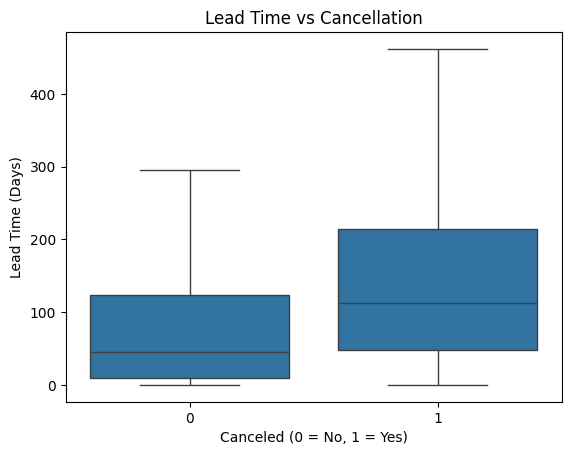

In [ ]:

sns.boxplot(
    data=df,
    x="is_canceled",
    y="lead_time",
    showfliers=False
)

plt.title("Lead Time vs Cancellation")
plt.xlabel("Canceled (0 = No, 1 = Yes)")
plt.ylabel("Lead Time (Days)")
plt.show()


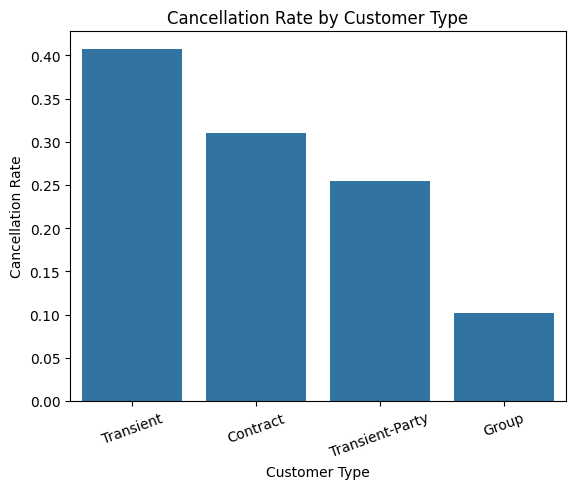

In [ ]:
sns.barplot(
    data=df,
    x="customer_type",
    y="is_canceled",
    errorbar=None
)

plt.title("Cancellation Rate by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Cancellation Rate")
plt.xticks(rotation=20)
plt.show()


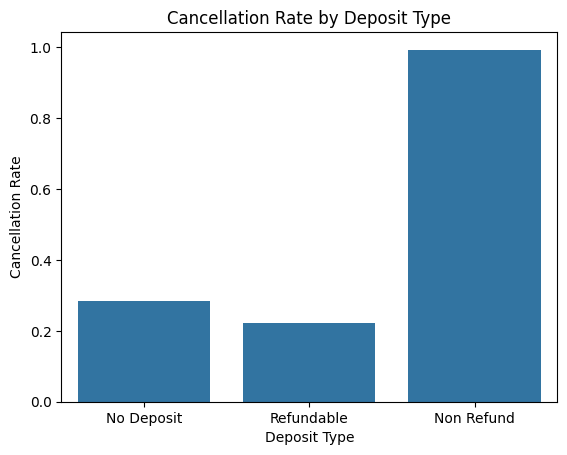

In [ ]:
sns.barplot(
    data=df,
    x="deposit_type",
    y="is_canceled",
    errorbar=None
)

plt.title("Cancellation Rate by Deposit Type")
plt.xlabel("Deposit Type")
plt.ylabel("Cancellation Rate")
plt.show()


### Step 7: Exploratory Data Analysis (EDA)

Exploratory Data Analysis was performed to investigate factors associated with hotel booking cancellations.

Four features were examined:

1. **Hotel Type:** To compare cancellation rates between City Hotels and Resort Hotels.
2. **Lead Time:** To investigate the relationship between booking lead time and cancellations.
3. **Customer Type:** To compare cancellation behavior across different customer categories.
4. **Deposit Type:** To investigate the relationship between deposit policies and cancellation rates.

These visualizations help identify patterns in customer booking behavior and support the selection of useful features for machine learning.

The observed relationships are associations and do not necessarily establish causation.

In [ ]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        solver="liblinear"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        random_state=42,
        n_jobs=-1
    )
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Models and cross-validation created!")


Models and cross-validation created!
